<a href="https://colab.research.google.com/github/siliverisrinithya-arch/SteelSight-AI/blob/main/steel_surface_defect_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Cell 1: Install Ultralytics and dependencies
%pip install -q ultralytics opencv-python-headless matplotlib pyyaml scikit-learn

In [6]:
# Cell 2: Mount Drive, extract dataset, and fix mismatched annotation
import os
import shutil
import zipfile
from pathlib import Path
from google.colab import drive

# 1. Mount Google Drive if available, else check local /content directory
if not os.path.exists('/content/drive'):
    try:
        drive.mount('/content/drive')
    except Exception:
        pass

# Check Drive first, then local /content
zip_path = Path("/content/drive/MyDrive/archive (2).zip")
if not zip_path.exists():
    zip_path = Path("/content/archive (2).zip")

if not zip_path.exists():
    raise FileNotFoundError("Could not find 'archive (2).zip' in Drive or /content. Please ensure it is uploaded.")

raw_extract_dir = Path("/content/industrial_defect_dataset")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(raw_extract_dir)

# 2. Fix the crazing_240.xml mismatch bug
dataset_root = raw_extract_dir / "NEU-DET"
train_img = dataset_root / "train/images/crazing/crazing_240.jpg"
val_xml = dataset_root / "validation/annotations/crazing_240.xml"
train_xml = dataset_root / "train/annotations/crazing_240.xml"

if train_img.exists() and val_xml.exists() and not train_xml.exists():
    shutil.move(str(val_xml), str(train_xml))
    print("Fixed: crazing_240.xml moved to train/annotations successfully.")
else:
    print("Dataset extracted and annotations verified.")

Mounted at /content/drive
Fixed: crazing_240.xml moved to train/annotations successfully.


In [7]:
# Cell 3: Convert XML annotations to normalized YOLO format
import xml.etree.ElementTree as ET

yolo_root = Path("/content/neu_yolo")
classes = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
class_to_id = {name: i for i, name in enumerate(classes)}

for split in ["train", "validation"]:
    img_dir = dataset_root / split / "images"
    xml_dir = dataset_root / split / "annotations"

    out_img_dir = yolo_root / "images" / split
    out_lbl_dir = yolo_root / "labels" / split
    out_img_dir.mkdir(parents=True, exist_ok=True)
    out_lbl_dir.mkdir(parents=True, exist_ok=True)

    img_lookup = {p.stem: p for p in img_dir.rglob("*") if p.suffix.lower() in [".jpg", ".jpeg", ".png"]}

    for xml_file in xml_dir.glob("*.xml"):
        if xml_file.stem not in img_lookup:
            continue

        src_img = img_lookup[xml_file.stem]
        tree = ET.parse(xml_file)
        root = tree.getroot()

        size = root.find("size")
        width = float(size.findtext("width"))
        height = float(size.findtext("height"))

        lines = []
        for obj in root.findall("object"):
            cname = obj.findtext("name")
            if cname not in class_to_id:
                continue
            box = obj.find("bndbox")
            xmin = max(0.0, min(float(box.findtext("xmin")), width))
            xmax = max(0.0, min(float(box.findtext("xmax")), width))
            ymin = max(0.0, min(float(box.findtext("ymin")), height))
            ymax = max(0.0, min(float(box.findtext("ymax")), height))

            if xmax <= xmin or ymax <= ymin:
                continue

            # Normalized YOLO center coordinates & dimensions
            xc = ((xmin + xmax) / 2.0) / width
            yc = ((ymin + ymax) / 2.0) / height
            bw = (xmax - xmin) / width
            bh = (ymax - ymin) / height

            lines.append(f"{class_to_id[cname]} {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")

        if lines:
            shutil.copy2(src_img, out_img_dir / src_img.name)
            (out_lbl_dir / f"{src_img.stem}.txt").write_text("\n".join(lines) + "\n", encoding="utf-8")

print(f"YOLO dataset conversion completed cleanly at: {yolo_root}")

YOLO dataset conversion completed cleanly at: /content/neu_yolo


In [8]:
# Cell 4: Create standardized YOLO configuration YAML
import yaml

data_config = {
    "path": str(yolo_root),
    "train": "images/train",
    "val": "images/validation",
    "names": {i: name for i, name in enumerate(classes)}
}

yaml_path = yolo_root / "data.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(data_config, f, sort_keys=False)

print(f"data.yaml configured at: {yaml_path}")

data.yaml configured at: /content/neu_yolo/data.yaml


In [ ]:
# Cell 5: Train YOLO11n on steel surface defects
from ultralytics import YOLO
import torch

device = 0 if torch.cuda.is_available() else "cpu"
model = YOLO("yolo11n.pt")

results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=320,
    batch=8,
    device=device,
    project="/content/industrial_defect_runs",
    name="defect_detection",
    patience=10,
    seed=42,
    save=True,
    plots=True
)
print("Training completed successfully!")

Ultralytics 8.4.202 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/neu_yolo/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=defect_detection, nbs=64, nms=None, opset=None, optimize=Fa

In [14]:
import pandas as pd

# Ultralytics saves the full, unbuffered log of every single epoch in results.csv
results_csv_path = "/content/industrial_defect_runs/defect_detection/results.csv"

# Load and clean column headers
df = pd.read_csv(results_csv_path)
df.columns = df.columns.str.strip()

print(f"Total Epochs Completed: {len(df)} / 50")
print("\n--- Final Epoch (Epoch 50) Exact Metrics ---")
print(df.tail(1)[['epoch', 'train/box_loss', 'train/cls_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)']])

Total Epochs Completed: 50 / 50

--- Final Epoch (Epoch 50) Exact Metrics ---
    epoch  train/box_loss  train/cls_loss  metrics/precision(B)  \
49     50         1.24982         1.08526               0.60991   

    metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  
49            0.70654           0.71557              0.38472  


In [13]:
import os

best_path = "/content/industrial_defect_runs/defect_detection/weights/best.pt"
last_path = "/content/industrial_defect_runs/defect_detection/weights/last.pt"

print("best.pt exists:", os.path.exists(best_path))
print("last.pt exists:", os.path.exists(last_path))

best.pt exists: True
last.pt exists: True


In [10]:
# Cell 6: Run validation and display detection metrics
best_weights = "/content/industrial_defect_runs/defect_detection/weights/best.pt"
trained_model = YOLO(best_weights)

metrics = trained_model.val(data=str(yaml_path), split="val", plots=True)

print("\n--- OBJECT DETECTION RESULTS ---")
print(f"Precision (P):  {metrics.box.mp * 100:.2f}%")
print(f"Recall (R):     {metrics.box.mr * 100:.2f}%")
print(f"mAP@50:         {metrics.box.map50 * 100:.2f}%")
print(f"mAP@50-95:      {metrics.box.map * 100:.2f}%")

Ultralytics 8.4.202 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 101 layers, 2,598,266 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 538.6±168.5 MB/s, size: 18.8 KB)
val: Scanning /content/neu_yolo/labels/validation.cache... 360 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 360/360 75.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 1.1s/it 24.2s
                   all        360        854      0.608      0.717      0.723      0.389
               crazing         60        162      0.592      0.367      0.478      0.204
             inclusion         71        159      0.682       0.81      0.834      0.466
               patches         73        193      0.825      0.865      0.913       0.59
        pitted_surface         60         87      0.672      0.759      0.803      0.467
       rolled-in_scale         60     


Plate-Level Classification Accuracy: 91.11%

                 precision    recall  f1-score   support

        crazing       1.00      0.68      0.81        60
      inclusion       1.00      0.94      0.97        64
        patches       0.95      0.94      0.95        66
 pitted_surface       0.89      0.98      0.93        50
rolled-in_scale       1.00      0.93      0.97        60
      scratches       1.00      1.00      1.00        60

      micro avg       0.97      0.91      0.94       360
      macro avg       0.97      0.91      0.94       360
   weighted avg       0.98      0.91      0.94       360



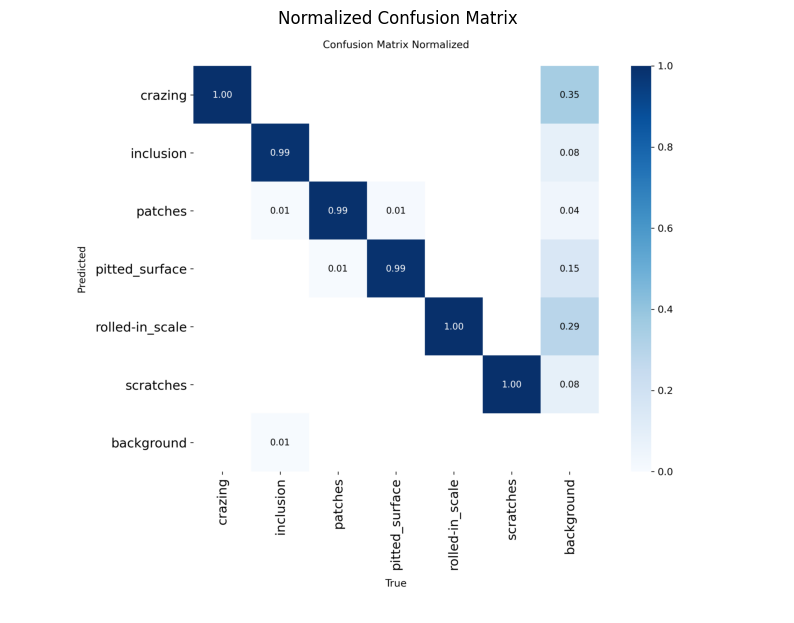

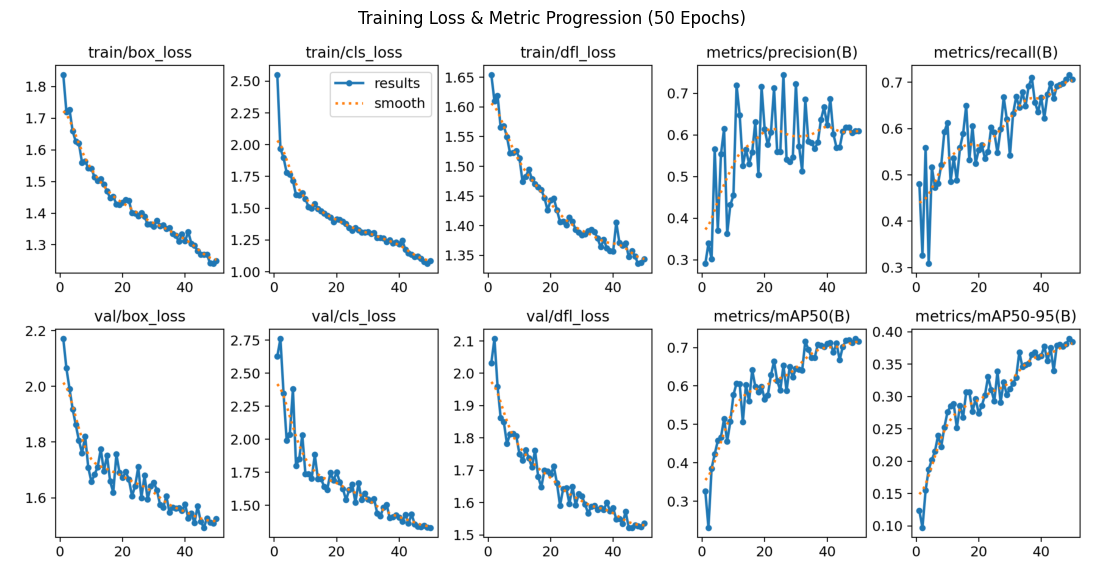

In [12]:
# Cell 7: Compute Plate-Level Classification Accuracy & Display Plots
import glob
import cv2
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, classification_report

val_img_dir = str(yolo_root / "images/validation")
val_lbl_dir = str(yolo_root / "labels/validation")

y_true, y_pred = [], []
image_paths = glob.glob(val_img_dir + "/*")

for path in image_paths:
    stem = Path(path).stem
    lbl_file = Path(val_lbl_dir) / f"{stem}.txt"
    if not lbl_file.exists():
        continue

    with open(lbl_file, "r") as f:
        lines = f.readlines()
    true_classes = [int(line.split()[0]) for line in lines if line.strip()]
    if not true_classes:
        continue

    # Majority ground truth label for the plate
    true_class = max(set(true_classes), key=true_classes.count)

    res = trained_model.predict(path, conf=0.25, verbose=False)
    boxes = res[0].boxes
    if boxes is not None and len(boxes) > 0:
        pred_class = int(boxes.cls[boxes.conf.argmax().item()].item())
    else:
        pred_class = -1

    y_true.append(true_class)
    y_pred.append(pred_class)

acc = accuracy_score(y_true, y_pred) * 100
print(f"\nPlate-Level Classification Accuracy: {acc:.2f}%\n")
print(classification_report(y_true, y_pred, labels=[0, 1, 2, 3, 4, 5], target_names=classes, zero_division=0))

# 1. Display Normalized Confusion Matrix
runs_dir = "/content/industrial_defect_runs/defect_detection"
cm_path = os.path.join(runs_dir, "confusion_matrix_normalized.png")
if os.path.exists(cm_path):
    plt.figure(figsize=(10, 8))
    plt.imshow(cv2.cvtColor(cv2.imread(cm_path), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Normalized Confusion Matrix")
    plt.show()

# 2. Display Training Metric & Loss Curves
results_plot = os.path.join(runs_dir, "results.png")
if os.path.exists(results_plot):
    plt.figure(figsize=(14, 10))
    plt.imshow(cv2.cvtColor(cv2.imread(results_plot), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title("Training Loss & Metric Progression (50 Epochs)")
    plt.show()
